In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

import tinycudann as tcnn

import tqdm

import importlib
import os
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")
    sys.path.append(os.getcwd() + "/../src/old")

import normalizing_flows
importlib.reload(normalizing_flows)
import normalizing_flows

In [2]:
domain = torch.tensor([[-2, 4], [0, 2]])

x = torch.tensor([1, 1])

y = (2 * x - domain[:, 0] - domain[:, 1]) / (domain[:, 1] - domain[:, 0])

res = (y + 1) / 2 * (domain[:, 1] - domain[:, 0]) + domain[:, 0]

print(y)

tensor([0., 0.])


In [3]:
B = 1
K = 2

enc_config = {
	"otype": "Composite",
	"nested": [
		{
			"n_dims_to_encode": 1, # Non-linear appearance dims.
			"otype": "OneBlob",
			"n_bins": 16
		},
		{
			# Number of remaining linear dims is automatically derived
			"otype": "Identity"
		},
	]
}

net_config = {
    "otype": "FullyFusedMLP",    # Component type.
    "activation": "ReLU",        # Activation of hidden layers.
    "output_activation": "None", # Activation of the output layer.
    "n_neurons": 32,            # Neurons in each hidden layer.
                                # May only be 16, 32, 64, or 128.
    "n_hidden_layers": 2,        # Number of hidden layers.
}

context_size = 0
batch_size = 1

device = 'cuda'

x = torch.rand((batch_size, 2), device = device)
context = torch.rand((batch_size, context_size), device = device)

num_flows = 2
flows = []
for i in range(num_flows):
    flows += [normalizing_flows.NeuralSplineFlow(B, K, context_size, enc_config, net_config)]


class NormalizingFlow(torch.nn.Module):
    def __init__(self, flows):
        super().__init__()
        self.flows = flows

    def permute(self, x):
        x[..., [0, 1]] = x[..., [1, 0]]
        return x
    
    def forward(self, z, context = None):
        for flow in self.flows:
            z, _ = flow(z, context=context)
            z = self.permute(z)

        if len(self.flows) % 2 != 0:
            return self.permute(z)

        return z
    
    def forward_and_log_det(self, z, context):
        log_det = torch.zeros(len(z), device=z.device)
    
        for flow in self.flows:
            z, log_d = flow(z, context=context)
            z = self.permute(z)
            log_det += log_d
            # print(f"log_d {log_d}")

        print(f"fwd z {z}")
        if len(self.flows) % 2 != 0:
            return self.permute(z), log_det

        return z, log_det
    
    def inverse(self, x, context):
        for i in range(len(self.flows) - 1, -1, -1):
            x = self.permute(x)
            x, _ = self.flows[i].inverse(x, context=context)
            
        if len(self.flows) % 2 != 0:
            return self.permute(x)

        return x

    def inverse_and_log_det(self, x, context):
        log_det = torch.zeros(len(x), device=x.device)

        for i in range(len(self.flows) - 1, -1, -1):
            x = self.permute(x)
            
            x, log_d = self.flows[i].inverse(x, context=context)
            log_det += log_d
            
        if len(self.flows) % 2 != 0:
            return self.permute(x), log_det

        return x, log_det

    def log_prob(self, x, context):
        log_q = torch.zeros(len(x), dtype=x.dtype, device=x.device)
        z = x

        for i in range(len(self.flows) - 1, -1, -1):
            z = self.permute(z)

            z, log_det = self.flows[i].inverse(z, context=context)
            log_q += log_det
            

        return log_q

model = NormalizingFlow(flows)

print(list(flows[0].parameters()))

y, log_det_1 = model.forward_and_log_det(x, context)

log_det_2 = model.log_prob(y.detach().clone(), context)

xx, log_det_3 = model.inverse_and_log_det(y.detach().clone(), context)

print()
print(f"x: {x}")
print(f"y: {y}")
print(f"xx: {xx}")

print()
print(log_det_1)
print(log_det_2)
print(log_det_3)

RuntimeError: [json.exception.type_error.306] cannot use value() with number

In [ ]:
B = 1
K = 2

flow = normalizing_flows.NeuralSplineFlow(B, K, 0, enc_config, net_config)

x = torch.tensor([[0, 0.3]], device = 'cuda')

y, log_det_y = flow(x, None)

x2, log_det_x = flow.inverse(y, None)

print(f"y {y}")
print(f"log_det_y {log_det_y}")
print(f"x {x}")
print(f"log_det_x {log_det_x}")

y tensor([[0.0000, 0.3943]], device='cuda:0', grad_fn=<CatBackward0>)
log_det_y tensor([-0.2673], device='cuda:0', grad_fn=<SqueezeBackward1>)
x tensor([[0.0000, 0.3000]], device='cuda:0')
log_det_x tensor([0.2673], device='cuda:0', grad_fn=<NegBackward0>)


100%|██████████| 1000/1000 [00:06<00:00, 166.31it/s]
C:\Users\janlu\AppData\Local\Temp\ipykernel_19616\2976911845.py:107: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


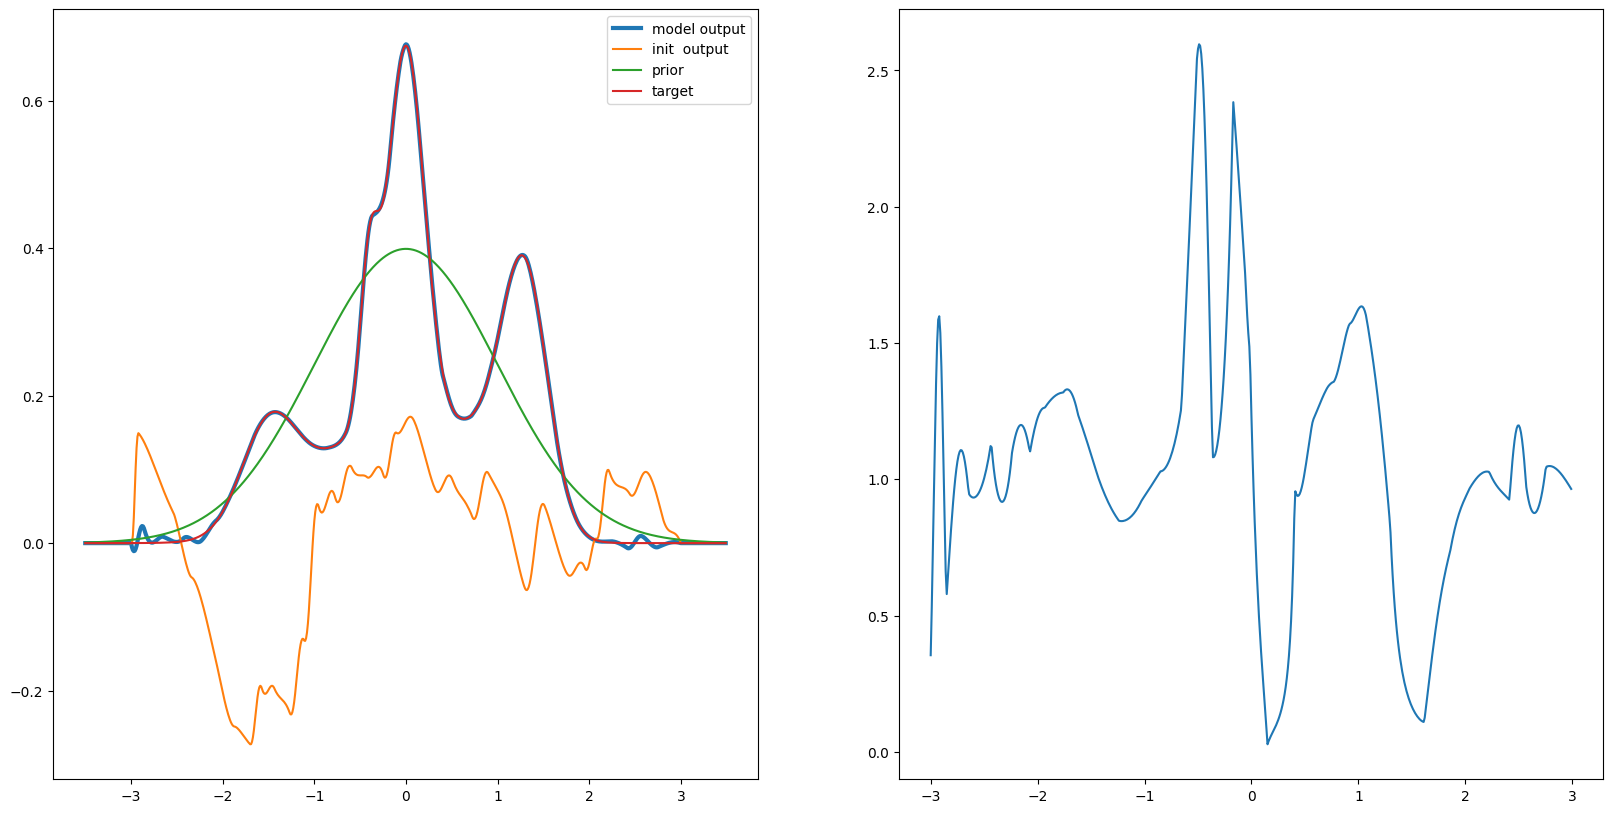

In [57]:
B = 3
K = 32

enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

m = torch.distributions.Normal(torch.tensor([0.0], device=device), torch.tensor([1.0], device=device))

means = torch.tensor([-1.5, -0.7, -0.4, 0, 0.1, 0.9, 1.3], device = device)
sigmas = torch.tensor([0.3, 0.6, 0.1, 0.2, 0.5, 0.4, 0.25], device = device)
weights = torch.tensor([2, 3, 1, 5, 3, 2, 4], device=device)


sigmas_squared = sigmas.square()
weights = torch.divide(weights, weights.sum())



def eval_gaussian(x, means, sigmas_squared, weights):
    diff_squared = (x.unsqueeze(-1) - means).squeeze(0).square()
    exponent = -0.5 * diff_squared / sigmas_squared
    norm_factor = 1 / torch.sqrt(2 * torch.pi * sigmas_squared)

    individal_pdf = weights * norm_factor * torch.exp(exponent)
    return individal_pdf.sum(dim = -1)

def target(x, k = 10.0):
    return eval_gaussian(x, means, sigmas_squared, weights)
    # return m.log_prob(x).exp()

class TestModel(torch.nn.Module):
    def __init__(self, B, K):
        super().__init__()
        self.model = torch.nn.Sequential(
            torch.nn.Linear(1, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 3 * K + 1)
        )
        self.B = B
        self.K = K

    def forward(self, x):
        output = self.model(x)
        vertices_x, vertices_y, knot_derivs = normalizing_flows.build_spline_params(output, self.B)
        return normalizing_flows.eval_quadratic_spline(vertices_x, vertices_y, knot_derivs, x)

        
    

model = TestModel(B, K)
model.to(device)

x = torch.arange(-B - 0.5, B + 0.5, 0.01, device=device)
x_inp = x.unsqueeze(-1)

y_init, log_det = model(x_inp)

pred_init = y_init - x_inp

loss_hist = np.array([])

opt = torch.optim.Adam(model.parameters(), lr =3e-2)
its = 1000
batch_size = 2 ** 14

iterator = tqdm.tqdm(range(its))
for it in iterator:
    opt.zero_grad()

    batch = m.sample((batch_size, ))
    # batch = -torch.rand((batch_size, 1), device = device) * 2 * B - B
    
    y, _ = model(batch)
    pred = y - batch
    t = target(batch)

    loss = torch.mean((pred - t) ** 2)
    loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())

    loss.backward()
    opt.step()



y, log_det = model(x_inp)

pred = y - x_inp


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

ax1.plot(x.detach().cpu(), pred.detach().cpu(),                     label='model output', linewidth=3.0)
ax1.plot(x.detach().cpu(), pred_init.detach().cpu(),                label='init  output')
ax1.plot(x.detach().cpu(), m.log_prob(x_inp).exp().detach().cpu(),  label='prior')
ax1.plot(x.detach().cpu(), target(x).detach().cpu(),                label='target')


ax2.plot(x[50:650].detach().cpu(), log_det[50:650].exp().detach().cpu(),            label='abs det')

# ax2.semilogy(loss_hist)
# ax2.set_title("Loss")


ax1.legend()
fig.show()

torch.Size([5])


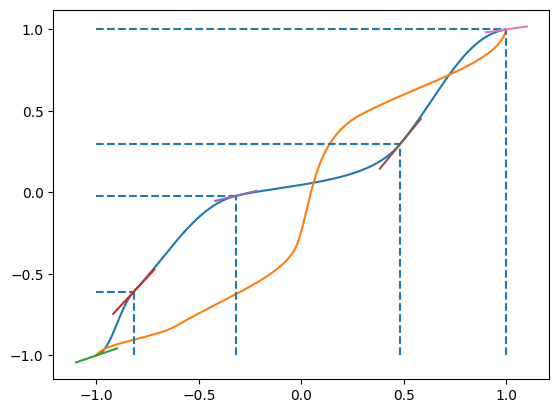

In [ ]:
from normalizing_flows import build_spline_params, eval_quadratic_spline, invert_quadratic_spline

def build_deriv_line(x, y, d, line_length):
    half_length = line_length / 2
    x_values = [x - half_length, x + half_length]
    y_values = [y - d * half_length, y + d * half_length]
    return x_values, y_values

widths = torch.tensor([0.6, 1.1, 1.3])
heights = torch.tensor([0.8, 1.0, 1.9])
derivs = torch.tensor([-0.8, 6.8])

# input = torch.cat((widths, heights, derivs))

K = 4
input = torch.randn((3 * K + 1))
input[0:2 * K] *= 0.5
input[2 * K: ] *= 2

input = input.unsqueeze(0)
vert_x, vert_y, knot_derivs = build_spline_params(input, 1.0)
vert_x = vert_x.squeeze(0)
vert_y = vert_y.squeeze(0)
knot_derivs = knot_derivs.squeeze(0)

print(knot_derivs.shape)

start = -1.0
end = 1.0
step_size = 0.01
xx = torch.arange(start, end, step_size)

yy, log_det = eval_quadratic_spline(vert_x, vert_y, knot_derivs, xx)
xx_2, inv_log_det = invert_quadratic_spline(vert_x, vert_y, knot_derivs, yy)

plt.plot(xx, yy)
plt.plot(yy, xx_2)
plt.vlines(x=vert_x, ymin=-1, ymax=vert_y, linestyles='dashed')
plt.hlines(y=vert_y, xmin=-1, xmax=vert_x, linestyles='dashed')


for i in range(K + 1):
    x, y = build_deriv_line(vert_x[i], vert_y[i], knot_derivs[i], 0.2)
    plt.plot(x, y)